In [1]:
#Import all importent depandancys
#LangGraph
# LangGraph
from langgraph.graph import StateGraph, START, END
# State management
from typing import TypedDict, Annotated
from IPython.display import Image, display

In [2]:
class AgentState(TypedDict):
      name:str
      age:int
      id:int
      input:int


In [3]:
def get_user(state: AgentState):
    users = {
        1: {"name": "ajay", "age": 27},
        2: {"name": "shubam", "age": 29}
    }

    user = users.get(state["id"], {"name": "Unknown", "age": 0})

    return {
        **user,
        "id": state["id"]
    }

In [4]:
def get_input(state: AgentState):
    return {"id": state["input"]}

In [5]:
def print_result (state: AgentState):
    print(f"user name is {state['name']}")

In [6]:
# init Graph 
graph= StateGraph(AgentState)



In [7]:
#Adding Nodes

graph.add_node("get_input",get_input);
graph.add_node("get_user",get_user);
graph.add_node("print_result",print_result);


In [8]:
# Adding Edge
graph.add_edge(START,"get_input");

graph.add_edge("get_input","get_user");
graph.add_edge("get_user","print_result");
graph.add_edge("print_result",END);

In [9]:
# Compile workflow
workflow = graph.compile()

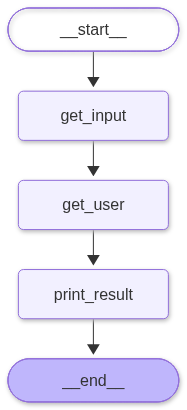

In [10]:
#Print Graph
display(
    Image(workflow.get_graph().draw_mermaid_png())
)

In [11]:
result = workflow.invoke({
    "input": 2
})


user name is shubam
